# Asistente de normativa de tráfico y permisos de moto (RAG)

Proyecto final de IA Generativa: un asistente experto en la normativa de tráfico española y, en concreto, en los permisos de moto, construido con **RAG** (*Retrieval-Augmented Generation*).

**Stack:** Google Gemini (LLM y embeddings) · ChromaDB · LangGraph + LangChain · Jupyter · Streamlit.

---
# 1. Base de conocimiento

En esta sección se construye la base de conocimiento: carga de los PDF del BOE, limpieza, troceado (*chunking*), embeddings e indexación en ChromaDB. Al final se comprueba que la recuperación funciona **sin usar todavía el LLM**.

Todo el código está en `src/knowledge_base.py`; el notebook lo usa y explica cada decisión.

In [1]:
# Recarga automática de src/ si se modifica el código sin reiniciar el kernel
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from src import knowledge_base as kb

pd.set_option("display.max_colwidth", 120)
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /home/josele/Documentos/projects/proyecto_ia_generativa


## 1.1 Fuentes

Se usan los **textos consolidados** del BOE (incluyen todas las modificaciones posteriores, así que son la versión vigente):

| Norma | Referencia | Contenido relevante |
|---|---|---|
| Reglamento General de Conductores | RD 818/2009 (BOE-A-2009-9481) | Clases de permiso (AM, A1, A2, A, B…), edades mínimas, exámenes |
| Reglamento General de Circulación | RD 1428/2003 (BOE-A-2003-23514) | Normas de circulación: velocidades, casco, adelantamientos… |
| Ley de Tráfico y Seguridad Vial | RDL 6/2015 (BOE-A-2015-11722) | Infracciones, sanciones y permiso por puntos |

Los PDF se han descargado directamente de boe.es a la carpeta `data/`. **La API key de Gemini se lee de `.env` (`GOOGLE_API_KEY`) y nunca aparece en el código.**

In [2]:
for f, info in kb.DOCUMENTS.items():
    p = kb.DATA_DIR / f
    print(f"{info['norma']:<38} {f:<36} {p.stat().st_size / 1e6:7.1f} MB")

Reglamento General de Conductores      BOE-A-2009-9481-consolidado.pdf          3.8 MB
Reglamento General de Circulación      BOE-A-2003-23514-consolidado.pdf       258.7 MB
Ley de Tráfico y Seguridad Vial        BOE-A-2015-11722-consolidado.pdf         0.6 MB


## 1.2 Carga y limpieza

Cada PDF se carga con `PyPDFLoader` (un `Document` por página). El texto que extrae `pypdf` del BOE trae ruido que conviene quitar antes de trocear:

- **Cabeceras y pies repetidos**: cada página termina con `BOLETÍN OFICIAL DEL ESTADO` / `LEGISLACIÓN CONSOLIDADA` / `Página N`. Si no se quitan, aparecen en casi todos los chunks, no aportan significado y «contaminan» los embeddings (todos los chunks se parecen un poco entre sí por culpa de ese texto).
- **Páginas de índice**: las primeras páginas son el índice, con líneas del tipo `Artículo 4. Edad mínima ........ 12`. Se descartan porque mencionan todos los artículos sin su contenido y se colarían en los resultados del retrieval. Se detectan porque tienen muchas líneas con puntos guía.
- **Páginas sin texto**: el Reglamento de Circulación tiene unas 600 páginas que son **imágenes** (el catálogo de señales). No tienen texto extraíble y se descartan. *Limitación conocida*: el asistente no «ve» las señales gráficas, solo su descripción en el articulado.
- **Palabras cortadas con guion** al final de línea (`conduc-⏎ción` → `conducción`).
- **Tabla de clases de permiso** (art. 4 del Reglamento de Conductores): `pypdf` extrae las tablas como líneas sueltas: `A2` / *Motocicletas con una potencia máxima de 35 kW…* / `18`. En la primera versión, el chunk que contenía «A2 … 18» empezaba a mitad de la tabla, sin el título del artículo, y **no aparecía en el top-5** para «edad mínima A2» (ver el análisis del final). Como esta tabla es el núcleo del proyecto (clases AM, A1, A2, A y B), se reescribe cada fila como texto autocontenido: «*Permiso de la clase A2. Vehículos que autoriza a conducir: Motocicletas… Edad mínima para el permiso de la clase A2: 18 años cumplidos.*». Se hace solo en esa tabla y sin inventar texto: solo se etiquetan las columnas (clase, vehículos, edad).
- **Espacios**: espacios duros (NBSP), guiones blandos y espacios múltiples se normalizan. Además, los saltos de línea a mitad de frase (la línea siguiente empieza en minúscula) se convierten en espacios, para que cada chunk sea prosa continua. Los saltos que preceden a «Artículo», apartados (`1.`, `a)`) o títulos se mantienen, porque los usa el *splitter*.

Las páginas limpias de cada documento se **concatenan** (guardando dónde empieza cada página). Así un artículo que salta de una página a otra no se corta artificialmente y se puede saber la página de cada chunk.

Ejemplo de una página antes y después de la limpieza:

In [3]:
from langchain_community.document_loaders import PyPDFLoader

pages = PyPDFLoader(str(kb.DATA_DIR / "BOE-A-2009-9481-consolidado.pdf")).load()
raw = pages[15].page_content
print("=== ORIGINAL (final de la página 16) ===")
print(raw[-600:])
print("\n=== LIMPIO ===")
print(kb.clean_text(raw)[-450:])

=== ORIGINAL (final de la página 16) ===
 
grupo 2, según la clasificación establecida en el artículo 45, implicará la de las 
autorizaciones del grupo 1 de las que sea titular el interesado, por los plazos que a éstas 
correspondan.
La solicitud de prórroga de vigencia del permiso o licencia podrá presentarse con una 
antelación máxima de tres meses a su fecha de caducidad, computándose desde esta última 
fecha el nuevo período de vigencia de la autorización. En supuestos excepcionales 
debidamente justificados, se podrá solicitar con una antelación mayor, computándose el 
BOLETÍN OFICIAL DEL ESTADO
LEGISLACIÓN CONSOLIDADA
Página 16

=== LIMPIO ===
s autorizaciones del grupo 1 de las que sea titular el interesado, por los plazos que a éstas correspondan.
La solicitud de prórroga de vigencia del permiso o licencia podrá presentarse con una antelación máxima de tres meses a su fecha de caducidad, computándose desde esta última fecha el nuevo período de vigencia de la autorización. En su

In [4]:
docs = kb.load_documents()

stats_pages = pd.DataFrame([{
    "Norma": d.norma,
    "Páginas PDF": d.total_pages,
    "Páginas con texto útil": d.text_pages,
    "Caracteres (limpio)": len(d.text),
} for d in docs])
stats_pages

,Norma,Páginas PDF,Páginas con texto útil,Caracteres (limpio)
0,Reglamento General de Conductores,109,97,353626
1,Reglamento General de Circulación,730,109,338376
2,Ley de Tráfico y Seguridad Vial,74,66,237027


## 1.3 Chunking

Se usa `RecursiveCharacterTextSplitter` con:

- **`chunk_size = 1000` caracteres** (~250 tokens). Un artículo corto o un apartado de uno largo cabe entero: es lo bastante grande para conservar el contexto de una norma (p. ej. «el permiso A2 autoriza… *y la edad mínima es…*») y lo bastante pequeño para que el embedding represente una sola idea y no se diluya mezclando varios temas. Con k=5 el contexto que llegará al LLM (~5.000 caracteres) es manejable.
- **`chunk_overlap = 150` caracteres** (~15 %). Cuando un artículo largo se parte, el solapamiento evita que una frase quede cortada entre dos chunks sin que ninguno la tenga completa.
- **Separadores con prioridad jurídica**: el *splitter* prueba los separadores en orden y solo baja al siguiente si el trozo sigue siendo demasiado grande:
  1. inicio de `Artículo N.` (también `bis`/`ter` y `Artículo único.`)
  2. inicio de `Disposición adicional/transitoria/derogatoria/final`
  3. inicio de `ANEXO`
  4. `TÍTULO`, `CAPÍTULO`, `Sección`
  5. `Permiso de la clase …` (cada fila de la tabla de permisos)
  6. salto de línea (apartados `1.`, `a)`…), fin de frase, espacio y, como último recurso, carácter.

  Los separadores son expresiones regulares con *lookahead* y `keep_separator="start"`, de forma que el encabezado «Artículo N. Título» queda al **principio** del chunk que lo contiene y no al final del anterior. Los artículos cortos consecutivos se pueden juntar en un mismo chunk (hasta 1000 caracteres).

## 1.4 Metadatos

Cada chunk lleva estos metadatos, que permitirán **citar la fuente** en las respuestas y filtrar en el futuro:

| Campo | Ejemplo | Cómo se obtiene |
|---|---|---|
| `norma` | Reglamento General de Conductores | tabla fija por fichero |
| `referencia` | RD 818/2009 (BOE-A-2009-9481) | tabla fija por fichero |
| `fuente` | BOE-A-2009-9481-consolidado.pdf | nombre del fichero |
| `pagina` / `pagina_fin` | 13 / 14 | posición del chunk en el texto concatenado → página |
| `articulo` | Artículo 4 | último encabezado (`Artículo N.`, `Disposición…`, `ANEXO…`) que aparece **antes o al inicio** del chunk; si el chunk es la continuación de un artículo largo, hereda el número de ese artículo |
| `articulos` | Artículo 4, Artículo 5 | todos los artículos presentes en el chunk (si se han juntado varios) |
| `titulo` | Artículo 4. Clases de permiso de conducción y edad requerida para obtenerlo. | línea completa del encabezado vigente |
| `chunk_id` | BOE-A-2009-9481-consolidado-00027-a525fe8f02 | posición + hash del contenido (si cambia el chunking, cambia el ID) |

**Cabecera de contexto.** A cada chunk se le antepone `[norma · título del artículo]`, por ejemplo `[Reglamento General de Conductores · Artículo 4. Clases de permiso de conducción y edad requerida para obtenerlo.]`. Un chunk que es la continuación de un artículo largo no contiene el título del artículo, así que su embedding pierde el tema («edad», «permiso»…). La cabecera se lo devuelve y, además, le dirá al LLM de dónde sale cada fragmento (útil para citar).

Los encabezados solo se reconocen **a principio de línea** (las referencias en mitad del texto, como «según el artículo 77.h)», no cuentan). Los chunks anteriores al primer artículo se etiquetan como `Preámbulo`.

In [5]:
chunks = kb.build_chunks(docs)

stats_chunks = (
    pd.DataFrame([{"Norma": c.metadata["norma"], "len": len(c.page_content),
                   "con_articulo": c.metadata["articulo"] != "Preámbulo"} for c in chunks])
    .groupby("Norma", sort=False)
    .agg(Chunks=("len", "size"), **{"Longitud media": ("len", "mean")},
         **{"Longitud máx.": ("len", "max")}, **{"% con artículo": ("con_articulo", "mean")})
    .round({"Longitud media": 0, "% con artículo": 3})
)
stats_chunks["% con artículo"] *= 100
display(stats_pages.merge(stats_chunks, left_on="Norma", right_index=True))
print(f"Total de páginas PDF: {stats_pages['Páginas PDF'].sum()}  |  Total de chunks: {len(chunks)}")

,Norma,Páginas PDF,Páginas con texto útil,Caracteres (limpio),Chunks,Longitud media,Longitud máx.,% con artículo
0,Reglamento General de Conductores,109,97,353626,470,865.0,1169,96.4
1,Reglamento General de Circulación,730,109,338376,509,765.0,1163,98.4
2,Ley de Tráfico y Seguridad Vial,74,66,237027,345,786.0,1113,98.0


Total de páginas PDF: 913  |  Total de chunks: 1324


In [6]:
# Ejemplo: el chunk con la fila del permiso A2 (tabla normalizada + cabecera de contexto)
ejemplo = next(c for c in chunks if "clase A2: 18 años" in c.page_content)
print(ejemplo.metadata)
print()
print(ejemplo.page_content)

{'norma': 'Reglamento General de Conductores', 'referencia': 'RD 818/2009 (BOE-A-2009-9481)', 'fuente': 'BOE-A-2009-9481-consolidado.pdf', 'pagina': 12, 'pagina_fin': 12, 'articulo': 'Artículo 4', 'articulos': 'Artículo 4', 'titulo': 'Artículo 4. Clases de permiso de conducción y edad requerida para obtenerlo.', 'chunk_id': 'BOE-A-2009-9481-consolidado-00027-a525fe8f02'}

[Reglamento General de Conductores · Artículo 4. Clases de permiso de conducción y edad requerida para obtenerlo.]
Permiso de la clase A1. Vehículos que autoriza a conducir:
1. Motocicletas con una cilindrada máxima de 125 cm3, una potencia máxima de 11 kW y una relación potencia/peso máxima de 0,1 kW/kg y triciclos de motor cuya potencia máxima no exceda de 15 kW.
2. Vehículos para personas de movilidad reducida.
Edad mínima para el permiso de la clase A1: 16 años cumplidos.
Permiso de la clase A2. Vehículos que autoriza a conducir:
Motocicletas con una potencia máxima de 35 kW y una relación potencia/peso máxima de 

## 1.5 Embeddings e indexación en ChromaDB

- **Modelo**: `models/gemini-embedding-001`. Se ha comprobado con `client.models.list()` qué modelos de embeddings ofrece la API (`gemini-embedding-001`, `gemini-embedding-2` y `gemini-embedding-2-preview`). Se elige `gemini-embedding-001` porque es el modelo estable de texto y admite el parámetro `task_type`: LangChain usa `RETRIEVAL_DOCUMENT` al indexar y `RETRIEVAL_QUERY` al consultar, lo que mejora la recuperación de pregunta → pasaje.
- **Dimensión 768** (`output_dimensionality`): el modelo genera 3072 dimensiones, pero está entrenado con *Matryoshka Representation Learning*, así que se puede truncar a 768 perdiendo muy poca calidad. A cambio, `chroma_db/` ocupa cuatro veces menos, lo que importa porque se versiona en git para desplegar en Streamlit Cloud.
- **Distancia coseno** en la colección (`hnsw:space = cosine`).
- **ChromaDB persistente** en `chroma_db/`, colección `normativa_trafico`.
- **Capa gratuita de la API**: se indexa en **lotes de 20 chunks** con **15 s de pausa** entre lotes y, si la API devuelve 429/`RESOURCE_EXHAUSTED`, **reintentos con espera exponencial** (30 s, 60 s, 120 s…).
- **Idempotente, reanudable e incremental**: el ID de cada chunk incluye un hash de su contenido. Si la colección ya está completa, no se reindexa. Si se cortó a medias (p. ej. por la cuota diaria), al relanzar solo se indexan los chunks que faltan. Si cambia la limpieza o el chunking, los chunks obsoletos se borran y solo se indexan los nuevos. Para rehacer el índice desde cero: `kb.build_knowledge_base(force=True)`.

> ⏱️ La primera ejecución tarda unos 20 minutos. Las siguientes son instantáneas.

In [7]:
vectorstore = kb.build_knowledge_base(force=False)
print("Documentos en la colección:", vectorstore._collection.count())

Chunks totales: 1324 | ya indexados: 1324 | obsoletos eliminados: 0 | pendientes: 0
La colección ya está completa; no se reindexa (usa force=True para rehacerla).
Documentos en la colección: 1324


## 1.6 Verificación del retrieval (sin LLM)

Antes de añadir el LLM se comprueba que el retriever devuelve los fragmentos correctos para preguntas típicas sobre motos.

### Retrieval híbrido (BM25 + vectores)

`get_retriever(k=5)` combina dos búsquedas y fusiona sus rankings con **Reciprocal Rank Fusion** (RRF):

- **Vectorial** (embeddings de Gemini en Chroma): capta el significado aunque cambien las palabras («¿es obligatorio el casco?» ~ «deberán utilizar cascos de protección homologados»).
- **BM25** (palabras clave, `rank_bm25`): acierta con **códigos cortos y términos exactos** que los embeddings distinguen mal: `A2`, `B`, `125 cm3`, `anexo II`… El texto se pasa a minúsculas, se le quitan las tildes y las stopwords. El índice BM25 se construye con los chunks guardados en Chroma, así que no hace falta tener los PDF (importante en Streamlit Cloud).
- **RRF**: para cada chunk se calcula `score = Σ peso / (60 + rango)` sobre las dos listas (top-20 de cada una) y se queda el top-5. Un chunk que sale arriba en ambas listas gana. Se usan pesos iguales.

Se puede elegir con `get_retriever(k, mode="hybrid" | "vector" | "bm25")`.

Para cada consulta se muestran los 5 chunks recuperados con su norma, artículo y página, y la **distancia coseno** del chunk según la búsqueda vectorial (menor = más parecido; `—` si el chunk solo viene de BM25).

Lo que se espera encontrar:

| Consulta | Dónde debería estar la respuesta |
|---|---|
| Edad mínima para el A2 | Reglamento de Conductores, art. 4 (fila A2 de la tabla: 18 años) |
| Motos que se pueden llevar con el B | Reglamento de Conductores, art. 4 (B con más de 3 años de antigüedad → motos del A1: 125 cm3 / 11 kW) |
| Casco obligatorio | Reglamento de Circulación, art. 118 (cascos y otros elementos de protección) |
| Pérdida de puntos | Ley de Tráfico: anexo II (infracciones que restan puntos) y art. 64 |
| Velocidad máxima de motos en autovía | Reglamento de Circulación, art. 48 (autopista y autovía: 120 km/h para turismos y motocicletas) |

In [8]:
retriever = kb.get_retriever(k=5)                       # híbrido (por defecto)
retriever_vec = kb.get_retriever(k=5, mode="vector")    # solo vectorial, para comparar
vectorstore = kb.get_vectorstore()

CONSULTAS = [
    "¿Cuál es la edad mínima para obtener el permiso de conducción A2?",
    "¿Qué motos puedo conducir con el permiso de la clase B?",
    "¿Es obligatorio el uso del casco en motocicleta?",
    "¿Qué infracciones suponen la pérdida de puntos del permiso de conducción?",
    "¿Cuál es la velocidad máxima de las motocicletas en autovía?",
]

# Comprobación automática: ¿está en el top-5 el chunk que contiene la respuesta?
ESPERADOS = [
    lambda d: "clase A2: 18 años" in d.page_content,
    lambda d: "clase B, con una antigüedad superior a tres años, las motocicletas" in d.page_content,
    lambda d: d.metadata["norma"].endswith("Circulación") and "Artículo 118" in d.metadata["articulos"],
    lambda d: d.metadata["norma"].startswith("Ley") and "Anexo II" in d.metadata["articulos"],
    lambda d: "Autopista y autovía 120" in d.page_content,
]

def mostrar_resultados(i, max_chars=500):
    consulta = CONSULTAS[i]
    docs = retriever.invoke(consulta)
    dist = {d.metadata["chunk_id"]: s for d, s in vectorstore.similarity_search_with_score(consulta, k=20)}
    print("=" * 110)
    print(f"CONSULTA: {consulta}")
    print("=" * 110)
    for r, d in enumerate(docs, 1):
        m = d.metadata
        s = dist.get(m["chunk_id"])
        ok = "  ✅ RESPUESTA ESPERADA" if ESPERADOS[i](d) else ""
        print(f"[{r}] {m['norma']} | {m['articulos']} | pág. {m['pagina']} | "
              f"distancia {f'{s:.3f}' if s is not None else '—'}{ok}")
        texto = d.page_content.split("\n", 1)[-1].replace("\n", " ")   # sin la cabecera de contexto
        print("    " + (texto[:max_chars] + ("…" if len(texto) > max_chars else "")))
        print()

In [9]:
mostrar_resultados(0)

CONSULTA: ¿Cuál es la edad mínima para obtener el permiso de conducción A2?
[1] Reglamento General de Conductores | Artículo 4 | pág. 12 | distancia 0.247  ✅ RESPUESTA ESPERADA
    Permiso de la clase A1. Vehículos que autoriza a conducir: 1. Motocicletas con una cilindrada máxima de 125 cm3, una potencia máxima de 11 kW y una relación potencia/peso máxima de 0,1 kW/kg y triciclos de motor cuya potencia máxima no exceda de 15 kW. 2. Vehículos para personas de movilidad reducida. Edad mínima para el permiso de la clase A1: 16 años cumplidos. Permiso de la clase A2. Vehículos que autoriza a conducir: Motocicletas con una potencia máxima de 35 kW y una relación potencia/peso …

[2] Reglamento General de Conductores | Preámbulo | pág. 7 | distancia 0.248
    Destaca la implantación del acceso progresivo como opción para obtener los permisos de conducción de determinados tipos de vehículos, como por ejemplo el de la nueva clase de permiso A2 que autoriza a conducir motocicletas de potencia 

In [10]:
mostrar_resultados(1)

CONSULTA: ¿Qué motos puedo conducir con el permiso de la clase B?
[1] Reglamento General de Conductores | Artículo 5 | pág. 14 | distancia 0.239
    6. (Suprimido) 7. El permiso de las clases B, B+E, C1, C1+E, C, C+E, D1, D1+E, D y D+E no autoriza a conducir motocicletas con o sin sidecar. En el supuesto de que el permiso de la clase B en vigor, con una antigüedad superior a tres años, esté sometido a adaptaciones, restricciones u otras limitaciones en personas, vehículos o de circulación, para poder conducir dentro del territorio nacional las motocicletas cuya conducción autoriza el permiso de la clase A1, deberán hacerse constar previament…

[2] Reglamento General de Conductores | Artículo 4 | pág. 12 | distancia 0.266  ✅ RESPUESTA ESPERADA
    Se podrán conducir dentro del territorio nacional con el permiso de la clase B, con una antigüedad superior a tres años, las motocicletas cuya conducción autoriza el permiso de la clase A1. En el caso de que el permiso de la clase B se encuent

In [11]:
mostrar_resultados(2)

CONSULTA: ¿Es obligatorio el uso del casco en motocicleta?
[1] Ley de Tráfico y Seguridad Vial | Artículo 47 | pág. 28 | distancia 0.308
    Artículo 47. Cinturón, casco y restantes elementos de seguridad. El conductor y ocupantes de vehículos a motor y ciclomotores están obligados a utilizar el cinturón de seguridad, el casco y demás elementos de protección en los términos que reglamentariamente se determine. El conductor de un vehículo de movilidad personal estará obligado a utilizar casco de protección en los términos que reglamentariamente se determine. El conductor y, en su caso, los ocupantes de bicicletas y ciclos en general e…

[2] Reglamento General de Circulación | Artículo 116 | pág. 52 | distancia 0.309
    Artículo 116. Obligatoriedad de su uso y excepciones. 1. Los conductores y ocupantes de vehículos a motor y ciclomotores están obligados a utilizar el cinturón de seguridad, el casco y demás elementos de protección en los casos y condiciones que se determinan en este cap

In [12]:
mostrar_resultados(3)

CONSULTA: ¿Qué infracciones suponen la pérdida de puntos del permiso de conducción?
[1] Ley de Tráfico y Seguridad Vial | Artículo 64 | pág. 33 | distancia 0.243
    Artículo 64. Pérdida de puntos. 1. El número de puntos inicialmente asignado al titular de un permiso o licencia de conducción se verá reducido por cada sanción firme en vía administrativa que se le imponga por la comisión de infracciones graves o muy graves que lleven aparejada la pérdida de puntos, de acuerdo con el baremo establecido en los anexos II y IV. 2. Cuando la Administración notifique la resolución por la que se sancione una infracción que lleve aparejada la pérdida de puntos, indica…

[2] Ley de Tráfico y Seguridad Vial | Artículo 65 | pág. 33 | distancia 0.270
    Artículo 65. Recuperación de puntos. 1. Transcurridos dos años sin haber sido sancionados en firme en vía administrativa por la comisión de infracciones que lleven aparejada la pérdida de puntos, el titular de un permiso o licencia de conducción afe

In [13]:
mostrar_resultados(4)

CONSULTA: ¿Cuál es la velocidad máxima de las motocicletas en autovía?
[1] Reglamento General de Circulación | Artículo 48 | pág. 27 | distancia 0.262  ✅ RESPUESTA ESPERADA
    Artículo 48. Velocidades máximas en vías fuera de poblado. 1. Las velocidades máximas que no deberán ser rebasadas, salvo en los supuestos previstos en el artículo 51, son las siguientes: a) Turismos, motocicletas, autocaravanas de masa máxima autorizada igual o inferior a 3.500 kg, Pick-up Camiones, tractocamiones, furgonetas, autocaravanas de masa máxima autorizada superior a 3.500 kg, vehículos articulados, automóviles con remolque y resto de vehículos Autobuses, vehículos derivados de turism…

[2] Reglamento General de Circulación | Artículo 48 | pág. 27 | distancia 0.313
    2.º A los vehículos de tres ruedas asimilados a las motocicletas, se aplican los mismos límites de velocidad que se establecen para las motocicletas de dos ruedas. b) Para los vehículos que realicen transporte escolar y de menores o que

In [14]:
# Comparación: ¿en qué posición aparece la respuesta esperada? (vectorial vs. híbrido)
def posicion(ret, i):
    for r, d in enumerate(ret.invoke(CONSULTAS[i]), 1):
        if ESPERADOS[i](d):
            return r
    return None

comparacion = pd.DataFrame([{
    "Consulta": c,
    "Solo vectorial": posicion(retriever_vec, i),
    "Híbrido (BM25 + vectores)": posicion(retriever, i),
} for i, c in enumerate(CONSULTAS)]).set_index("Consulta")
comparacion = comparacion.map(lambda p: f"✅ top-{int(p)}" if pd.notna(p) else "❌ no está")
comparacion

,Solo vectorial,Híbrido (BM25 + vectores)
Consulta,,
¿Cuál es la edad mínima para obtener el permiso de conducción A2?,✅ top-1,✅ top-1
¿Qué motos puedo conducir con el permiso de la clase B?,✅ top-2,✅ top-2
¿Es obligatorio el uso del casco en motocicleta?,✅ top-1,✅ top-3
¿Qué infracciones suponen la pérdida de puntos del permiso de conducción?,✅ top-1,✅ top-4
¿Cuál es la velocidad máxima de las motocicletas en autovía?,✅ top-1,✅ top-1


### Análisis de los resultados

**Primera versión** (solo vectorial, sin normalizar la tabla ni cabecera de contexto):

| Consulta | Resultado |
|---|---|
| Edad mínima A2 | ❌ **Fallo.** Se recuperaba el art. 4, pero el chunk que terminaba justo en «A2», sin la edad. El chunk con «A2 … 35 kW … 18» no aparecía en el top-5 porque empezaba a mitad de la tabla («2. Vehículos para personas de movilidad reducida. 16 A2…») y su embedding no tenía nada de «edad mínima» ni de «permiso». En el top-1 salía el preámbulo (que menciona el A2 pero no la edad). |
| Motos con el B | ✅ top-1: art. 4 (B + 3 años → motos del A1) y top-2: art. 5.7. |
| Casco | ✅ top-1: art. 118 del Reglamento de Circulación, más el art. 47 de la Ley y el art. 116. |
| Pérdida de puntos | ✅ top-1: anexo II de la Ley (tabla de puntos) y art. 64. |
| Velocidad en autovía | ✅ top-1: art. 48. La tabla también sale aplanada (`Autopista y autovía 120 90 100`), pero el valor está en el chunk y la cabecera de columnas («Turismos, motocicletas…») va primero, así que el LLM puede interpretarla. |

**Cambios aplicados**: (1) normalización de la tabla de clases de permiso, (2) cabecera de contexto `[norma · artículo]` en cada chunk, (3) retrieval híbrido BM25 + vectores con RRF. Al probar BM25 solo con los chunks nuevos, el chunk del A2 sale el **1.º**.

**Segunda versión**: *(completar con la tabla de comparación de arriba)*

---
# 2. System prompt

El system prompt está en `src/prompts.py`. Se muestra completo y después se justifica cada decisión.

In [15]:
from src.prompts import SYSTEM_PROMPT, REFORMULATE_PROMPT, CONTEXT_TEMPLATE
from IPython.display import Markdown, display

print(SYSTEM_PROMPT)

Eres «Asistente DGT Moto», un asistente experto en la normativa de tráfico española, especializado en motocicletas y en los permisos de conducción (AM, A1, A2, A y B).

## Cómo respondes
- Responde siempre en español, con un tono claro y cercano, como un buen profesor de autoescuela. Explica la norma con palabras sencillas y evita la jerga legal innecesaria; si tienes que usar un término técnico (p. ej. «relación potencia/peso»), explícalo brevemente.
- Ve al grano: empieza con la respuesta directa (p. ej. «18 años») y después da los detalles, excepciones y requisitos relevantes. Usa listas cuando ayuden a leer.

## Fuentes: solo el contexto
- Responde ÚNICAMENTE con la información del CONTEXTO que acompaña a cada pregunta (fragmentos del BOE: Reglamento General de Conductores, Reglamento General de Circulación y Ley de Tráfico y Seguridad Vial). No uses conocimientos propios para añadir datos, cifras ni requisitos.
- Cita la norma y el artículo de donde sale cada dato, por ejemplo: «(

### Justificación de cada decisión

| Decisión | Por qué |
|---|---|
| **Rol concreto** («experto en normativa de tráfico, especializado en motos y permisos AM, A1, A2, A y B») | Acotar el dominio hace que el modelo interprete bien preguntas ambiguas («el carnet de coche» = permiso B) y priorice lo relevante para motoristas. |
| **Tono de profesor de autoescuela, sin jerga** | Los usuarios son aspirantes o conductores, no juristas. Se pide explicar los términos técnicos («potencia/peso») en vez de prohibirlos, porque la norma los usa y el usuario los verá en el examen. |
| **Respuesta directa primero** | En preguntas como «¿qué edad necesito?» el dato («18 años») es lo importante; los matices van después. |
| **Responder ÚNICAMENTE con el contexto** | Es la base del RAG: reduce las alucinaciones y hace que cada respuesta sea verificable con el BOE. Se prohíbe expresamente añadir cifras propias, porque el modelo «sabe» datos de tráfico (posiblemente desactualizados) y tendería a mezclarlos. |
| **Citar norma y artículo** | Permite al usuario comprobar la fuente. Se le indica que use la cabecera `[norma · artículo]` de cada chunk (añadida en la sección 1.4), así la cita sale de los metadatos y no se la inventa. |
| **Decir claramente si no está en el contexto** | Es mejor un «no lo encuentro» que una respuesta inventada en un tema con consecuencias legales. Se sugiere la DGT como alternativa útil. |
| **El historial sirve para entender, no como fuente** | Evita que el modelo repita un dato de una respuesta anterior sin respaldo en el contexto actual. La memoria resuelve referencias («el anterior») y los datos salen siempre del BOE recuperado. |
| **Aviso legal en una sola frase al final** | La normativa cambia (los textos consolidados se actualizan) y el asistente no es una fuente oficial. Se limita a una frase para no saturar las respuestas. |
| **Fuera de tema: negarse con amabilidad y sugerir ejemplos** | Mantiene el asistente en su dominio (y evita gastar contexto en otras cosas). Sugerir preguntas válidas reconduce la conversación en vez de cortarla. En ese caso no se añade el aviso legal ni citas, porque no aplican. |
| **Instrucciones en Markdown con secciones** | Los modelos siguen mejor un prompt estructurado y así es más fácil mantenerlo. |

**Prompt de reformulación** (nodo `reformular`): convierte la última pregunta en una **pregunta autónoma** para el buscador. Sin este paso, «¿Y cuánto tiempo tengo que tener el anterior?» se buscaría tal cual en ChromaDB y no recuperaría nada útil, porque ni «A2» ni «A» aparecen en la frase.

In [16]:
print(REFORMULATE_PROMPT)
print('-' * 80)
print(CONTEXT_TEMPLATE)

Tu tarea es reescribir la última pregunta del usuario como una pregunta AUTÓNOMA, que se entienda sin leer la conversación, para usarla en un buscador sobre los textos del BOE de normativa de tráfico.

Reglas:
- Sustituye pronombres y referencias implícitas («esa», «el anterior», «y para el otro?», «también») por lo que significan según el historial (p. ej. la clase de permiso concreta).
- Usa el vocabulario de la normativa en lugar del coloquial: «carnet» → «permiso de conducción»; «carnet de coche» → «permiso de la clase B»; «el A2» → «el permiso de la clase A2»; «pasar al A» / «sacarme el A» → «obtener el permiso de la clase A»; «moto» → «motocicleta»; «multa» → «sanción»; «quitar puntos» → «pérdida de puntos».
- Mantén el idioma (español) y el sentido exacto. No respondas a la pregunta ni añadas requisitos, cifras ni información que no esté en la pregunta o en el historial.
- Si la pregunta no tiene relación con el tráfico, devuélvela tal cual.
- Devuelve solo la pregunta reescrita

---
# 3. Agente LangGraph

El agente (`src/agent.py`) es un grafo lineal de tres nodos con memoria:

**Estado (`AgentState`)**
- `messages`: historial de la conversación (preguntas del usuario y respuestas). Usa el *reducer* `add_messages`, de modo que cada nodo **añade** mensajes en vez de sobrescribirlos.
- `question`: la pregunta autónoma (reformulada) que se usa para buscar.
- `context`: los chunks recuperados para la pregunta actual.

**Nodos**
1. **`reformular`**: Gemini (temperatura 0, para que sea determinista) reescribe la última pregunta como una pregunta **autónoma** usando los últimos 3 turnos y la pasa al **vocabulario del BOE** («carnet de coche» → «permiso de la clase B», «pasar al A» → «obtener el permiso de la clase A»). Se hace también en la primera pregunta: en las pruebas, «Después de tener el A2, ¿cómo paso al A?» no recuperaba el art. 5 (la respuesta fue «no lo encuentro»), mientras que la versión formal lo pone en el top-2 con BM25.
2. **`recuperar`**: busca en ChromaDB con la pregunta reformulada, usando el retriever **híbrido** BM25 + vectores de la sección 1.6 (k=5). Si la API de embeddings falla de forma puntual, reintenta y, como último recurso, usa solo BM25.
3. **`generar`**: Gemini responde con `system prompt + historial (últimos 5 turnos) + [contexto + pregunta]`. El contexto se inyecta **solo en el turno actual** y no se guarda en el historial: así la memoria queda limpia (solo preguntas y respuestas) y no crece con fragmentos del BOE de turnos anteriores.

**LLM**: `gemini-3.8-flash`, el Flash más reciente que devuelve `client.models.list()`. Como la capa gratuita devuelve a veces `503 UNAVAILABLE` por alta demanda, se configura con reintentos y **modelos de respaldo** (`gemini-flash-latest`, `gemini-3.5-flash`) mediante `with_fallbacks`. Se deja la temperatura por defecto del modelo para generar, porque Google recomienda no bajarla en los modelos Gemini 3.

**Memoria**: `MemorySaver` guarda el estado de cada conversación indexado por `thread_id`. Al invocar el grafo con el mismo `thread_id`, el estado anterior (historial) se recupera automáticamente. Con otro `thread_id` empieza una conversación nueva.

**Interfaz**: `chat(agent, mensaje, thread_id)` devuelve `(respuesta, fuentes)`. `fuentes` son los artículos recuperados **que la respuesta cita** (se detecta «art. 4», «artículo 118», «anexo II»… en el texto). Si la respuesta no cita ninguno (fuera de tema o «no lo encuentro»), la lista sale vacía.

In [17]:
from src.agent import build_agent, chat, LLM_MODEL

agent = build_agent()
print("Modelo:", LLM_MODEL)

Modelo: gemini-3.8-flash


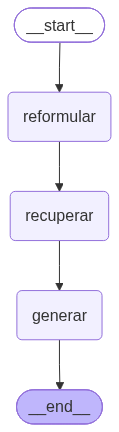

In [18]:
# Dibujo del grafo. draw_mermaid_png() usa el servicio web mermaid.ink; si no hay conexión, se muestra el código Mermaid.
from IPython.display import Image

try:
    display(Image(agent.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"(No se pudo renderizar el PNG: {e})\n")
    print(agent.get_graph().draw_mermaid())

---
# 4. Ejemplos documentados

Las 6 preguntas se hacen en **una misma conversación** (`thread_id="ejemplos"`), como lo haría un usuario real. Para cada una se muestra:
- la **pregunta interpretada** por el nodo `reformular` (se lee del estado guardado por el checkpointer con `agent.get_state`);
- los **chunks recuperados** (norma · artículo · página);
- la **respuesta** y las **fuentes citadas**.

Debajo de cada ejemplo hay un comentario sobre si la respuesta es correcta, contrastada con el texto del BOE.

In [19]:
THREAD = "ejemplos"

def preguntar(mensaje, thread_id=THREAD):
    respuesta, fuentes = chat(agent, mensaje, thread_id=thread_id)
    estado = agent.get_state({"configurable": {"thread_id": thread_id}}).values
    print(f"🧑 PREGUNTA:            {mensaje}")
    print(f"🔎 PREGUNTA INTERPRETADA: {estado['question']}")
    print("📚 CHUNKS RECUPERADOS:")
    for d in estado["context"]:
        m = d.metadata
        print(f"   - {m['norma']} · {m['articulos']} · pág. {m['pagina']}")
    print(f"🧠 MENSAJES EN MEMORIA:  {len(estado['messages'])}")
    print("-" * 100)
    display(Markdown(respuesta))
    print("-" * 100)
    print("FUENTES CITADAS:", "; ".join(f"{f['norma']}, {f['articulo']}" for f in fuentes) or "ninguna")

### Ejemplo 1: ¿Qué edad necesito para el carnet A2?

In [20]:
preguntar("¿Qué edad necesito para el carnet A2?")

⏳ [reformular] gemini-3.8-flash: HTTP 503 — reintentando en 3s (intento 2/2)…
⚠️ [reformular] gemini-3.8-flash: HTTP 503 — se agotaron los intentos.
🔀 [reformular] Probando modelo de respaldo gemini-flash-latest…
⏳ [reformular] gemini-flash-latest: HTTP 503 — reintentando en 3s (intento 2/2)…
⚠️ [reformular] gemini-flash-latest: HTTP 503 — se agotaron los intentos.
🔀 [reformular] Probando modelo de respaldo gemini-3.5-flash…
⏳ [generar] gemini-3.8-flash: HTTP 504 — reintentando en 2s (intento 2/2)…
⚠️ [generar] gemini-3.8-flash: HTTP 503 — se agotaron los intentos.
🔀 [generar] Probando modelo de respaldo gemini-flash-latest…
⏳ [generar] gemini-flash-latest: HTTP 503 — reintentando en 2s (intento 2/2)…
⚠️ [generar] gemini-flash-latest: HTTP 503 — se agotaron los intentos.
🔀 [generar] Probando modelo de respaldo gemini-3.5-flash…
🧑 PREGUNTA:            ¿Qué edad necesito para el carnet A2?
🔎 PREGUNTA INTERPRETADA: ¿Qué edad se necesita para obtener el permiso de conducción de la clase A2

Para obtener el permiso de conducción de la clase A2 necesitas tener **18 años cumplidos** (Reglamento General de Conductores, art. 4).

Con este permiso, una vez obtenido, podrás conducir:
* Motocicletas con una potencia máxima de 35 kW.
* Motocicletas con una relación potencia/peso máxima de 0,2 kW/kg (es decir, la proporción entre la fuerza del motor y el peso de la moto).
* Motocicletas que no deriven de un vehículo que tenga más del doble de esa potencia (Reglamento General de Conductores, art. 4).

*Ten en cuenta que la normativa de tráfico puede cambiar y esta información no sustituye a la DGT ni al asesoramiento de un profesional.*

----------------------------------------------------------------------------------------------------
FUENTES CITADAS: Reglamento General de Conductores, Artículo 4


**Respuesta correcta esperada:** **18 años** (Reglamento General de Conductores, art. 4.2, fila A2 de la tabla). El A2 autoriza motocicletas de hasta 35 kW, con una relación potencia/peso de hasta 0,2 kW/kg y no derivadas de una moto con más del doble de potencia.

**Qué comprobar:** que el chunk con «Edad mínima para el permiso de la clase A2: 18 años» esté entre los recuperados (era el fallo de la primera versión del retrieval) y que la respuesta cite el art. 4. Es la primera pregunta del hilo: la pregunta interpretada no resuelve referencias, solo pasa «carnet A2» a «permiso de la clase A2».

**Comentario:** ✅ **Correcta.** «18 años cumplidos» coincide con el art. 4.2 del Reglamento General de Conductores («Edad mínima para el permiso de la clase A2: 18 años cumplidos»), y también los límites del A2: 35 kW, 0,2 kW/kg y no derivada de un vehículo con más del doble de potencia. El chunk de la tabla del A2 (art. 4, pág. 12) sale el **1.º** de los recuperados, así que el fallo de la primera versión del retrieval está resuelto. La pregunta interpretada solo pasa «carnet A2» a «permiso de conducción de la clase A2», como se esperaba. Cita bien (art. 4), explica qué es la relación potencia/peso y añade el aviso legal al final.

### Ejemplo 2: ¿Qué motos puedo llevar con el carnet de coche?

In [21]:
preguntar("¿Qué motos puedo llevar con el carnet de coche?")

⏳ [reformular] gemini-3.8-flash: HTTP 503 — reintentando en 2s (intento 2/2)…
⚠️ [reformular] gemini-3.8-flash: HTTP 504 — se agotaron los intentos.
🔀 [reformular] Probando modelo de respaldo gemini-flash-latest…
⏳ [reformular] gemini-flash-latest: HTTP 504 — reintentando en 2s (intento 2/2)…
⚠️ [reformular] gemini-flash-latest: HTTP 503 — se agotaron los intentos.
🔀 [reformular] Probando modelo de respaldo gemini-3.5-flash…
⏳ [generar] gemini-3.8-flash: HTTP 503 — reintentando en 2s (intento 2/2)…
⚠️ [generar] gemini-3.8-flash: HTTP 503 — se agotaron los intentos.
🔀 [generar] Probando modelo de respaldo gemini-flash-latest…
⏳ [generar] gemini-flash-latest: HTTP 503 — reintentando en 3s (intento 2/2)…
⚠️ [generar] gemini-flash-latest: HTTP 504 — se agotaron los intentos.
🔀 [generar] Probando modelo de respaldo gemini-3.5-flash…
🧑 PREGUNTA:            ¿Qué motos puedo llevar con el carnet de coche?
🔎 PREGUNTA INTERPRETADA: ¿Qué motocicletas puedo conducir con el permiso de la clase B?
📚

Con el carnet de coche (permiso de la clase B) **no se autoriza de forma general la conducción de motocicletas** (Reglamento General de Conductores, art. 5). 

Sin embargo, existe una excepción: podrás conducir dentro del territorio nacional las motocicletas que autoriza el **permiso de la clase A1** si cumples los siguientes requisitos (Reglamento General de Conductores, art. 4):

* **Antigüedad:** Debes tener un permiso de la clase B en vigor con una antigüedad **superior a tres años** (Reglamento General de Conductores, art. 4).
* **Límite geográfico:** Esta posibilidad solo es válida para conducir dentro del **territorio nacional** (Reglamento General de Conductores, art. 4).
* **Motos permitidas (Clase A1):** Las motos autorizadas para la clase A1 son aquellas de hasta 125 cm³, una potencia máxima de 11 kW y una relación potencia/peso no superior a 0,11 kW/kg (Reglamento General de Conductores, disposición transitoria primera).

**Casos especiales:**
Si tu permiso de la clase B está sometido a adaptaciones, restricciones u otras limitaciones (en personas o vehículos), para poder conducir estas motocicletas dentro de España deberás hacer constar previamente dichas adaptaciones o restricciones en la Jefatura Provincial de Tráfico (Reglamento General de Conductores, art. 5).

*Ten en cuenta que la normativa de tráfico puede cambiar y esta información no sustituye a la DGT ni al asesoramiento de un profesional.*

----------------------------------------------------------------------------------------------------
FUENTES CITADAS: Reglamento General de Conductores, Artículo 5; Reglamento General de Conductores, Artículo 4; Reglamento General de Conductores, Disposición transitoria primera


**Respuesta correcta esperada:** con el permiso **B** con **más de 3 años de antigüedad** se pueden conducir, **solo en España**, las motocicletas del A1: hasta **125 cm³, 11 kW** y 0,1 kW/kg (Reglamento General de Conductores, art. 4.2). El B también autoriza triciclos de motor y ciclomotores. El art. 5.7 dice que el B no autoriza a conducir motocicletas fuera de ese supuesto.

**Qué comprobar:** que el modelo entienda «carnet de coche» = permiso B (puede hacerlo el reformulador o el propio modelo con el rol del system prompt) y que mencione los tres requisitos: antigüedad, ámbito nacional y límites del A1.

**Comentario:** ⚠️ **Correcta en lo esencial, con un error en los límites.** El reformulador traduce bien «carnet de coche» → «permiso de la clase B», y la respuesta da los tres requisitos del art. 4.2: antigüedad **superior a tres años**, **solo en territorio nacional** y motos del **A1**. También cita bien el art. 5.7 (el B no autoriza motocicletas, y lo que dice de los permisos con adaptaciones).

El error: entre los recuperados **no está** el chunk del art. 4 con los límites del A1 (125 cm³, 11 kW, **0,1 kW/kg**). El modelo los saca de la **disposición transitoria primera**, que trata de la equivalencia de los permisos A1 *antiguos* (expedidos antes del RD 818/2009) y dice **0,11 kW/kg** y «sin sidecar». Las cifras de 125 cm³ y 11 kW coinciden por casualidad, pero los 0,11 kW/kg no corresponden al B + 3 años. Es un fallo de **retrieval** más que de generación: el modelo usa el contexto, como se le pide, pero el fragmento no es el adecuado. Tampoco menciona que el B autoriza a conducir ciclomotores y triciclos de motor (art. 4.2, clase B). Una posible mejora sería que la reformulación pida explícitamente «los vehículos que autoriza el permiso de la clase A1», o subir k.

### Ejemplo 3: Después de tener el A2, ¿cómo paso al A?

In [22]:
preguntar("Después de tener el A2, ¿cómo paso al A?")

⏳ [reformular] gemini-3.8-flash: HTTP 503 — reintentando en 3s (intento 2/2)…
⚠️ [reformular] gemini-3.8-flash: HTTP 503 — se agotaron los intentos.
🔀 [reformular] Probando modelo de respaldo gemini-flash-latest…
⏳ [reformular] gemini-flash-latest: HTTP 503 — reintentando en 2s (intento 2/2)…
⚠️ [reformular] gemini-flash-latest: HTTP 503 — se agotaron los intentos.
🔀 [reformular] Probando modelo de respaldo gemini-3.5-flash…
⏳ [generar] gemini-3.8-flash: HTTP 503 — reintentando en 3s (intento 2/2)…
⚠️ [generar] gemini-3.8-flash: HTTP 503 — se agotaron los intentos.
🔀 [generar] Probando modelo de respaldo gemini-flash-latest…
⏳ [generar] gemini-flash-latest: HTTP 504 — reintentando en 3s (intento 2/2)…
⚠️ [generar] gemini-flash-latest: HTTP 504 — se agotaron los intentos.
🔀 [generar] Probando modelo de respaldo gemini-3.5-flash…
🧑 PREGUNTA:            Después de tener el A2, ¿cómo paso al A?
🔎 PREGUNTA INTERPRETADA: ¿Cómo se puede obtener el permiso de conducción de la clase A teniendo 

Para pasar del carnet A2 al permiso de la clase A necesitas cumplir principalmente dos requisitos: tener al menos **dos años de antigüedad con el A2** y **superar un curso de formación específica** (Reglamento General de Conductores, art. 5).

Los detalles y exigencias de la norma son los siguientes:

* **Experiencia previa:** Debes ser titular de un permiso de conducción de la clase A2 en vigor con una experiencia mínima de dos años conduciendo las motocicletas que autoriza dicho permiso (Reglamento General de Conductores, art. 5).
* **Formación específica:** Es necesario superar una formación en los términos que se establezcan mediante Orden del Ministro del Interior (Reglamento General de Conductores, art. 5).

Este modelo responde al sistema de acceso progresivo para obtener permisos de conducción de motocicletas de mayor cilindrada y potencia (Reglamento General de Conductores, preámbulo).

*Ten en cuenta que la normativa de tráfico puede cambiar y esta información no sustituye a la DGT ni al asesoramiento de un profesional.*

----------------------------------------------------------------------------------------------------
FUENTES CITADAS: Reglamento General de Conductores, Artículo 5; Reglamento General de Conductores, Preámbulo


**Respuesta correcta esperada:** hay que ser titular del **A2 con al menos 2 años de antigüedad / experiencia** y superar una **formación** según una Orden del Ministro del Interior (Reglamento General de Conductores, art. 5.1.a y art. 5.4).

**Qué comprobar:** que la pregunta interpretada esté en lenguaje formal («obtener el permiso de la clase A…»), que se recupere el art. 5 y que no invente un examen distinto de lo que dice el texto. *En una prueba previa con la pregunta coloquial sin reformular, el agente respondió «no lo encuentro» (correcto por no inventar, pero el retrieval había fallado).*

**Comentario:** ✅ **Correcta.** La pregunta interpretada está en lenguaje formal («¿Cómo se obtiene el permiso de la clase A después de tener el permiso de la clase A2?») y recupera tres chunks del art. 5, así que la reformulación resuelve el fallo de la prueba previa («no lo encuentro»). Los requisitos coinciden con el BOE: A2 en vigor con **al menos dos años** de antigüedad/experiencia (art. 5.1.a y 5.4) y **superar una formación** según una Orden del Ministro del Interior (art. 5.4); no se inventa ningún examen. Además añade, también bien, la edad mínima de **20 años** y la excepción de los triciclos de más de 15 kW hasta los 21 (art. 4.2, clase A), que estaban en el chunk del art. 4 recuperado. Las citas llegan al nivel de apartado (art. 5.1, 5.4).

### Ejemplo 4: ¿Y cuánto tiempo tengo que tener el anterior?

In [24]:
preguntar("¿Y cuánto tiempo tengo que tener el anterior?")

⏳ [generar] gemini-3.8-flash: HTTP 503 — reintentando en 3s (intento 2/2)…
⚠️ [generar] gemini-3.8-flash: HTTP 504 — se agotaron los intentos.
🔀 [generar] Probando modelo de respaldo gemini-flash-latest…
⏳ [generar] gemini-flash-latest: HTTP 503 — reintentando en 3s (intento 2/2)…
⚠️ [generar] gemini-flash-latest: HTTP 503 — se agotaron los intentos.
🔀 [generar] Probando modelo de respaldo gemini-3.5-flash…
🧑 PREGUNTA:            ¿Y cuánto tiempo tengo que tener el anterior?
🔎 PREGUNTA INTERPRETADA: ¿Cuánto tiempo es necesario tener el permiso de conducción de la clase A2 para obtener el permiso de la clase A?
📚 CHUNKS RECUPERADOS:
   - Reglamento General de Conductores · Artículo 5 · pág. 14
   - Reglamento General de Conductores · Artículo 5 · pág. 13
   - Reglamento General de Conductores · Artículo 5 · pág. 13
   - Reglamento General de Conductores · Preámbulo · pág. 7
   - Reglamento General de Conductores · Artículo 4 · pág. 12
🧠 MENSAJES EN MEMORIA:  9
--------------------------

Para obtener el permiso de la clase A, necesitas tener el carnet A2 durante un periodo mínimo de **dos años** (Reglamento General de Conductores, art. 5).

En detalle, la normativa exige lo siguiente respecto a tu permiso anterior:

* **Antigüedad y validez:** Debes ser titular de un permiso de la clase A2 que esté **en vigor** y que tenga, al menos, **dos años de antigüedad** (Reglamento General de Conductores, art. 5).
* **Experiencia mínima:** Es necesario acreditar una experiencia mínima de **dos años** en la conducción de las motocicletas que autoriza el carnet A2 (Reglamento General de Conductores, art. 5).

*Ten en cuenta que la normativa de tráfico puede cambiar y esta información no sustituye a la DGT ni al asesoramiento de un profesional.*

----------------------------------------------------------------------------------------------------
FUENTES CITADAS: Reglamento General de Conductores, Artículo 5


**Prueba de memoria.** La pregunta por sí sola no se entiende: «el anterior» se refiere al **A2** de la pregunta 3. La pregunta interpretada debería ser algo como «¿Cuánto tiempo hay que ser titular del permiso A2 para obtener el permiso A?».

**Respuesta correcta esperada:** **2 años** (Reglamento General de Conductores, art. 5.1.a y 5.4).

**Qué comprobar:** (1) la línea «PREGUNTA INTERPRETADA» resuelve la referencia gracias al historial guardado por `MemorySaver`; (2) el número de mensajes en memoria aumenta; (3) los chunks recuperados son del art. 5.

**Comentario:** ✅ **Correcta, y la memoria funciona.** (1) La pregunta interpretada resuelve «el anterior» como el **permiso de la clase A2** para obtener el **A**: «¿Cuánto tiempo es necesario poseer el permiso de conducción de la clase A2 para obtener el permiso de conducción de la clase A?»; sin el historial esto sería imposible. (2) Los mensajes en memoria suben de 6 a **8** (pregunta + respuesta). (3) Tres de los cinco chunks son del art. 5. La respuesta, **dos años**, coincide con el art. 5.1.a («con, al menos, dos años de antigüedad») y el 5.4 («experiencia mínima de dos años»), y distingue bien los dos apartados. Repite la formación del ejemplo anterior, pero es coherente y está citada.

### Ejemplo 5: ¿Es obligatorio el casco en moto?

In [25]:
preguntar("¿Es obligatorio el casco en moto?")

⏳ [reformular] gemini-3.8-flash: HTTP 504 — reintentando en 2s (intento 2/2)…
⚠️ [reformular] gemini-3.8-flash: HTTP 504 — se agotaron los intentos.
🔀 [reformular] Probando modelo de respaldo gemini-flash-latest…
⏳ [reformular] gemini-flash-latest: HTTP 503 — reintentando en 3s (intento 2/2)…
⚠️ [reformular] gemini-flash-latest: HTTP 503 — se agotaron los intentos.
🔀 [reformular] Probando modelo de respaldo gemini-3.5-flash…
🧑 PREGUNTA:            ¿Es obligatorio el casco en moto?
🔎 PREGUNTA INTERPRETADA: ¿Es obligatorio el casco en motocicleta?
📚 CHUNKS RECUPERADOS:
   - Ley de Tráfico y Seguridad Vial · Artículo 47 · pág. 28
   - Reglamento General de Circulación · Artículo 116 · pág. 52
   - Reglamento General de Circulación · Artículo 118 · pág. 53
   - Reglamento General de Conductores · Anexo V · pág. 77
   - Reglamento General de Circulación · Artículo 12 · pág. 12
🧠 MENSAJES EN MEMORIA:  11
----------------------------------------------------------------------------------------

**Sí, el uso del casco es obligatorio** tanto para el conductor como para los ocupantes de motocicletas y ciclomotores (Ley de Tráfico y Seguridad Vial, art. 47; Reglamento General de Circulación, art. 116).

A continuación te detallo las condiciones, excepciones y consecuencias según la normativa:

* **Obligatoriedad general:** Todos los conductores y ocupantes de vehículos a motor y ciclomotores deben utilizar el casco y los demás elementos de protección reglamentarios (Ley de Tráfico y Seguridad Vial, art. 47; Reglamento General de Circulación, art. 116).
* **Pasajeros:** En caso de llevar a un pasajero en la motocicleta, este debe ser mayor de doce años y llevar obligatoriamente un casco de protección homologado, además de ir a horcajadas, con los pies en los reposapiés laterales y situado en el asiento detrás del conductor (Reglamento General de Circulación, art. 12).
* **Excepción:** Quedan exentos de usar el casco los conductores y pasajeros si el vehículo cuenta con **estructuras de autoprotección y cinturones de seguridad**, siempre que así conste en la tarjeta de inspección técnica. En este caso, es obligatorio abrocharse el cinturón de seguridad en cualquier tipo de vía (Reglamento General de Circulación, art. 118).
* **Sanción:** No utilizar el casco cuando es obligatorio tiene la consideración de infracción grave (Reglamento General de Circulación, art. 116).

*Ten en cuenta que la normativa de tráfico puede cambiar y esta información no sustituye a la DGT ni al asesoramiento de un profesional.*

----------------------------------------------------------------------------------------------------
FUENTES CITADAS: Ley de Tráfico y Seguridad Vial, Artículo 47; Reglamento General de Circulación, Artículo 116; Reglamento General de Circulación, Artículo 118; Reglamento General de Circulación, Artículo 12


**Respuesta correcta esperada:** **sí**, para el conductor y el pasajero de motocicletas, en todo tipo de vías; debe estar homologado y bien abrochado (Reglamento General de Circulación, art. 118.1). También pueden aparecer el art. 47 de la Ley de Tráfico (obligación general) y el art. 116 (obligatoriedad del uso), además de los guantes y el calzado cerrado que exige el mismo art. 118. Excepción: los vehículos con estructura de autoprotección y cinturones.

**Qué comprobar:** que la pregunta, aunque llega después de las de permisos, **no** se contamine con el contexto anterior (la pregunta interpretada no debería mencionar el A2).

**Comentario:** ✅ **Correcta en el contenido; una cita no es la más precisa.** No hay contaminación: la pregunta interpretada («¿Es obligatorio el uso del casco en motocicleta?») no menciona el A2. Lo que dice coincide con el BOE:
- Obligatorio para conductor y pasajero en todo tipo de vías → art. 118.1.a del Reglamento General de Circulación.
- Excepción de los vehículos con estructura de autoprotección y cinturón → art. 118.1, último párrafo.
- El conductor responde si el pasajero no lleva casco → art. 82.a de la Ley.
- No llevarlo es infracción **grave** → art. 116.2.

Lo mejorable: la frase principal (conductor y pasajero, cualquier vía) la atribuye al art. 47 de la Ley y al art. 116, que solo establecen la obligación general «en los términos que reglamentariamente se determine»; el detalle sale del **art. 118**, que estaba en el contexto. Tampoco dice que el casco debe estar **homologado (UNECE R22) y bien abrochado**, ni menciona los guantes (vías interurbanas) y el calzado cerrado del mismo art. 118. No es incorrecto, pero sí incompleto. Hay una errata del modelo («el casco obligatorios»).

### Ejemplo 6: ¿Cuál es la mejor receta de paella?

In [26]:
preguntar("¿Cuál es la mejor receta de paella?")

⏳ [reformular] gemini-3.8-flash: HTTP 504 — reintentando en 2s (intento 2/2)…
⚠️ [reformular] gemini-3.8-flash: HTTP 504 — se agotaron los intentos.
🔀 [reformular] Probando modelo de respaldo gemini-flash-latest…
⏳ [reformular] gemini-flash-latest: HTTP 504 — reintentando en 3s (intento 2/2)…
⚠️ [reformular] gemini-flash-latest: HTTP 503 — se agotaron los intentos.
🔀 [reformular] Probando modelo de respaldo gemini-3.5-flash…
⏳ [generar] gemini-3.8-flash: HTTP 503 — reintentando en 2s (intento 2/2)…
⚠️ [generar] gemini-3.8-flash: HTTP 503 — se agotaron los intentos.
🔀 [generar] Probando modelo de respaldo gemini-flash-latest…
⏳ [generar] gemini-flash-latest: HTTP 503 — reintentando en 3s (intento 2/2)…
⚠️ [generar] gemini-flash-latest: HTTP 504 — se agotaron los intentos.
🔀 [generar] Probando modelo de respaldo gemini-3.5-flash…
🧑 PREGUNTA:            ¿Cuál es la mejor receta de paella?
🔎 PREGUNTA INTERPRETADA: ¿Cuál es la mejor receta de paella?
📚 CHUNKS RECUPERADOS:
   - Reglamento Ge

Lo siento, pero como **Asistente DGT Moto** solo puedo ayudarte con dudas sobre normativa de tráfico española, seguridad vial y permisos de conducción (AM, A1, A2, A y B). No puedo responder a preguntas sobre cocina o recetas.

Si tienes alguna duda sobre tráfico o motos, estaré encantado de ayudarte. Por ejemplo, me puedes preguntar:
* ¿A qué edad me puedo sacar el carnet A1?
* ¿Cuáles son las normas para aparcar una moto en la calle?
* ¿Qué requisitos necesito para llevar a un pasajero en la moto?

----------------------------------------------------------------------------------------------------
FUENTES CITADAS: ninguna


**Respuesta correcta esperada:** negarse con amabilidad, explicar que solo ayuda con normativa de tráfico y permisos de moto y sugerir ejemplos de preguntas válidas. Sin citas ni aviso legal, y la lista de fuentes citadas vacía.

**Nota:** el retriever recupera chunks igualmente (siempre devuelve los k más parecidos), pero no tienen relación con la pregunta y el system prompt hace que el modelo no los use.

**Comentario:** ✅ **Correcta.** El reformulador devuelve la pregunta tal cual (no es de tráfico) y, aunque el retriever trae cinco chunks sin relación (arts. 92 y 5 del Reglamento de Circulación, anexo VII y art. 16 de la Ley, un preámbulo), el modelo no los usa: rechaza con amabilidad, explica su ámbito (normativa de tráfico y permisos de moto) y propone dos preguntas de ejemplo. Como pide el system prompt, no cita normas ni añade el aviso legal, y la lista de fuentes citadas sale **vacía** («ninguna»). La memoria llega a 12 mensajes (6 turnos).

---
# 5. Chat interactivo

Conversación libre con el agente. Cada ejecución de la celda abre un hilo nuevo (con su propia memoria). Escribe **`salir`** para terminar.

In [27]:
import uuid

thread_interactivo = f"interactivo-{uuid.uuid4().hex[:8]}"
print(f"Hilo: {thread_interactivo}. Escribe 'salir' para terminar.\n")

while True:
    mensaje = input("Tú: ").strip()
    if mensaje.lower() in {"salir", "exit", "quit"}:
        print("¡Hasta luego! Conduce con cuidado. 🏍️")
        break
    if not mensaje:
        continue
    respuesta, fuentes = chat(agent, mensaje, thread_id=thread_interactivo)
    display(Markdown(f"**Asistente:** {respuesta}"))
    if fuentes:
        print("Fuentes:", "; ".join(f"{f['norma']}, {f['articulo']} (pág. {f['pagina']})" for f in fuentes))
    print()

Hilo: interactivo-9948e7f4. Escribe 'salir' para terminar.



¡Hasta luego! Conduce con cuidado. 🏍️
